In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import classification_report ,r2_score,mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [84]:
url="https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
data=pd.read_csv(url)
data

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [86]:
x=data[['displacement']]
y=data['mpg']
y

0      18.0
1      15.0
2      18.0
3      16.0
4      17.0
       ... 
393    27.0
394    44.0
395    32.0
396    28.0
397    31.0
Name: mpg, Length: 398, dtype: float64

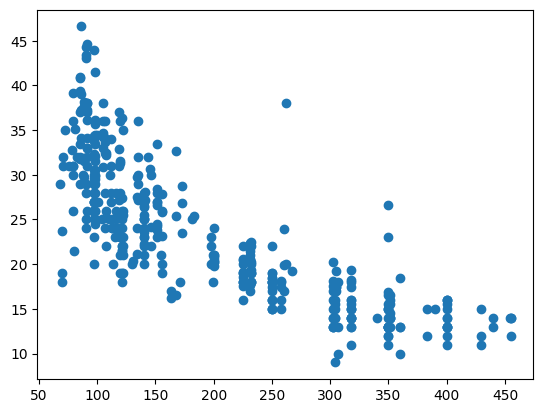

In [87]:
plt.scatter(
    x,y)
plt.show()

In [88]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    random_state=42,
    test_size=0.2)


In [89]:
linear_model=LinearRegression()
linear_model.fit(x_train,y_train)
y_pred=linear_model.predict(x_test)
R2_score=r2_score(y_test,y_pred)
mse_score=mean_squared_error(y_test,y_pred)


In [90]:
results=[]
results.append({
    "models":"Linear regression",
    "degree":1,
    "R2":R2_score,
    "mse":mse_score})
print(results)

[{'models': 'Linear regression', 'degree': 1, 'R2': 0.6633114869465596, 'mse': 18.102543998358946}]


In [95]:
polynomial_model={}
for degree in range(2,6):
    poly_model=PolynomialFeatures(degree=degree)
    x_train_poly=poly_model.fit_transform(x_train)
    x_test_poly=poly_model.transform(x_test)
    poly=LinearRegression()
    poly.fit(x_train_poly,y_train)
    y_pred_poly=poly.predict(x_test_poly)
    polynomial_model[degree]={
        "poly":poly,
        "poly_model":poly_model}
    r2_poly=r2_score(y_test,y_pred_poly)
    mse_poly=mean_squared_error(y_test,y_pred_poly)
    results.append({
        "models":"Polynomial regression",
        "degree":degree,
        "R2":r2_poly,
        "mse":mse_poly
})

result_table=pd.DataFrame(results)
polynomial_model
 
    

{2: {'poly': LinearRegression(), 'poly_model': PolynomialFeatures()},
 3: {'poly': LinearRegression(), 'poly_model': PolynomialFeatures(degree=3)},
 4: {'poly': LinearRegression(), 'poly_model': PolynomialFeatures(degree=4)},
 5: {'poly': LinearRegression(), 'poly_model': PolynomialFeatures(degree=5)}}

In [92]:
x_plot=pd.DataFrame({
    'displacement':np.linspace(
    x['displacement'].min(),
    x['displacement'].max(),
    300)})
y_plot=linear_model.predict(x_plot)


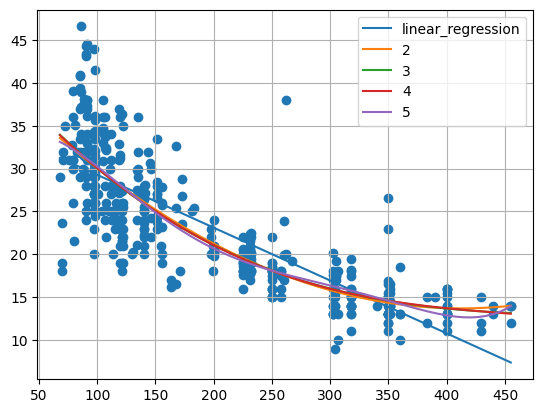

In [101]:
plt.scatter(
    x['displacement'],
    y)
plt.plot(
    x_plot['displacement'],
    y_plot,
label="linear_regression")

for degree in range(2,6):
    poly=polynomial_model[degree]['poly']
    model=polynomial_model[degree]['poly_model']
    x_plot_poly=model.transform(x_plot)
    y_plot_poly=poly.predict(x_plot_poly)
    plt.plot(
    x_plot['displacement'],
    y_plot_poly,
    label=f"{degree}"    
    )
plt.legend()
plt.grid(True)